# QuickBasket - Grocery Data Exploratory Data Analysis

## Task 1: Exploratory Data Analysis

**Objective**: Perform comprehensive exploratory data analysis on QuickBasket grocery order dataset

**Dataset Overview**: This dataset contains grocery order information including:
- Order metadata (user_id, order timing, etc.)
- Order items (products, reorder status)
- Product catalog (names, aisles, departments)
- Reference data (aisles and departments)

---

### The output required is in the final block of the notebook. Please run the entire python notebook before viewing the result. The python notebook also contains some additional analysis that was conducted to check the code as well as explore different things.

In [33]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# Set plotting style
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 8)

print("Libraries imported successfully!")


Libraries imported successfully!


In [34]:

# Load all datasets
print("Loading datasets...")

# Load reference data
aisles = pd.read_csv('aisle_info.csv')
departments = pd.read_csv('department_info.csv')
products = pd.read_csv('product_catalog.csv')

# Load and combine order metadata files
order_metadata_files = ['order_metadata.csv']

order_metadata_list = []
for file in order_metadata_files:
    df = pd.read_csv(file)
    order_metadata_list.append(df)
order_metadata = pd.concat(order_metadata_list, ignore_index=True)

# Load and combine order items files
order_items_train_files = ['order_items__train.csv']

order_items_prior_files = ['order_items__prior.csv']

order_items_train_list = []
order_items_prior_list = []

for file in order_items_train_files:
    df = pd.read_csv(file)
    order_items_train_list.append(df)

for file in order_items_prior_files:
    df = pd.read_csv(file)
    order_items_prior_list.append(df)

order_items_train = pd.concat(order_items_train_list, ignore_index=True)
order_items_prior = pd.concat(order_items_prior_list, ignore_index=True)
order_items = pd.concat([order_items_train, order_items_prior], ignore_index=True)

print(f"Data loaded successfully!")
print(f"Order metadata: {order_metadata.shape}")
print(f"Order items: {order_items.shape}")
print(f"Products: {products.shape}")
print(f"Aisles: {aisles.shape}")
print(f"Departments: {departments.shape}")


Loading datasets...
Data loaded successfully!
Order metadata: (3421083, 7)
Order items: (33819106, 4)
Products: (49688, 4)
Aisles: (134, 2)
Departments: (21, 2)


In [35]:

### 2. Dataset Overview and Structure

print("=== DATASET OVERVIEW ===")
print("\n1. Order Metadata:")
print(f"   - Shape: {order_metadata.shape}")
print(f"   - Columns: {list(order_metadata.columns)}")
print(f"   - Unique users: {order_metadata['user_id'].nunique()}")
print(f"   - Unique orders: {order_metadata['order_id'].nunique()}")

print("\n2. Order Items:")
print(f"   - Shape: {order_items.shape}")
print(f"   - Columns: {list(order_items.columns)}")
print(f"   - Unique products in orders: {order_items['product_id'].nunique()}")

print("\n3. Products:")
print(f"   - Shape: {products.shape}")
print(f"   - Columns: {list(products.columns)}")

print("\n4. Aisles:")
print(f"   - Shape: {aisles.shape}")
print(f"   - Sample aisles:")
print(aisles.head())

print("\n5. Departments:")
print(f"   - Shape: {departments.shape}")
print(f"   - All departments:")
print(departments)

=== DATASET OVERVIEW ===

1. Order Metadata:
   - Shape: (3421083, 7)
   - Columns: ['order_id', 'user_id', 'eval_set', 'order_number', 'order_dow', 'order_hour_of_day', 'days_since_prior_order']
   - Unique users: 206209
   - Unique orders: 3421083

2. Order Items:
   - Shape: (33819106, 4)
   - Columns: ['order_id', 'product_id', 'add_to_cart_order', 'reordered']
   - Unique products in orders: 49685

3. Products:
   - Shape: (49688, 4)
   - Columns: ['product_id', 'product_name', 'aisle_id', 'department_id']

4. Aisles:
   - Shape: (134, 2)
   - Sample aisles:
   aisle_id                       aisle
0         1       prepared soups salads
1         2           specialty cheeses
2         3         energy granola bars
3         4               instant foods
4         5  marinades meat preparation

5. Departments:
   - Shape: (21, 2)
   - All departments:
    department_id       department
0               1           frozen
1               2            other
2               3         

In [36]:

### 3. Data Quality Assessment

print("=== DATA QUALITY ASSESSMENT ===")
print("\n1. Missing Values Analysis:")
print("\nOrder Metadata missing values:")
print(order_metadata.isnull().sum())

print("\nOrder Items missing values:")
print(order_items.isnull().sum())

print("\nProducts missing values:")
print(products.isnull().sum())

print("\n2. Data Types:")
print("\nOrder Metadata data types:")
print(order_metadata.dtypes)

print("\n3. Duplicate Analysis:")
print(f"Duplicate orders in metadata: {order_metadata.duplicated().sum()}")
print(f"Duplicate order items: {order_items.duplicated().sum()}")


=== DATA QUALITY ASSESSMENT ===

1. Missing Values Analysis:

Order Metadata missing values:
order_id                       0
user_id                        0
eval_set                       0
order_number                   0
order_dow                      0
order_hour_of_day              0
days_since_prior_order    206209
dtype: int64

Order Items missing values:
order_id             0
product_id           0
add_to_cart_order    0
reordered            0
dtype: int64

Products missing values:
product_id       0
product_name     0
aisle_id         0
department_id    0
dtype: int64

2. Data Types:

Order Metadata data types:
order_id                    int64
user_id                     int64
eval_set                   object
order_number                int64
order_dow                   int64
order_hour_of_day           int64
days_since_prior_order    float64
dtype: object

3. Duplicate Analysis:
Duplicate orders in metadata: 0
Duplicate order items: 0


=== ORDER PATTERNS ANALYSIS ===
Merged dataset shape: (33819106, 10)


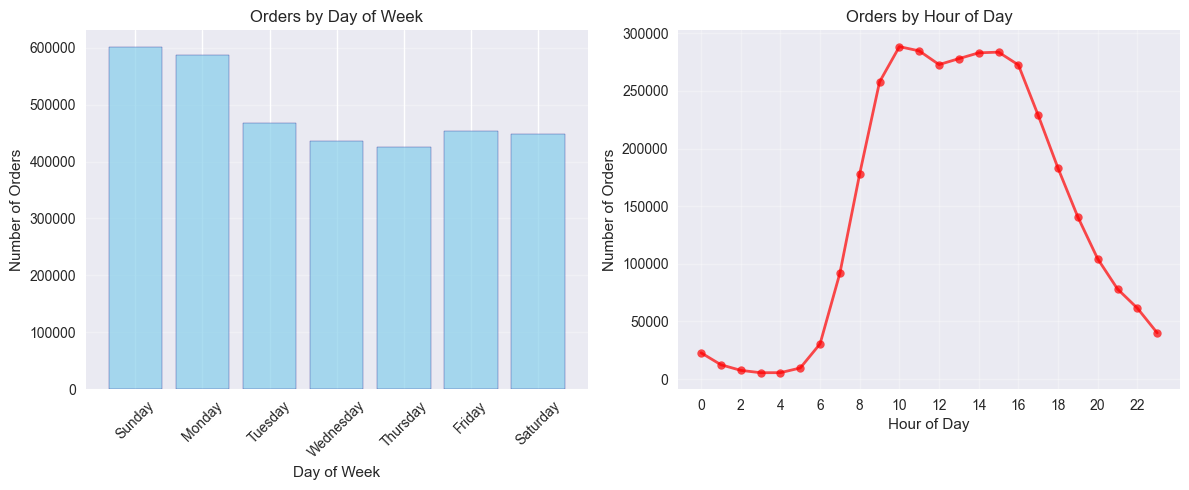


Peak ordering day: Sunday (600905 orders)
Peak ordering hour: 10:00 (288418 orders)


In [37]:

### 4. Order Patterns Analysis

print("=== ORDER PATTERNS ANALYSIS ===")

# Create merged dataset for analysis
orders_with_items = order_items.merge(order_metadata, on='order_id')
print(f"Merged dataset shape: {orders_with_items.shape}")

# 4.1 Orders by Day of Week
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
dow_counts = order_metadata['order_dow'].value_counts().sort_index()
days = ['Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday']
plt.bar(range(7), dow_counts.values, color='skyblue', edgecolor='navy', alpha=0.7)
plt.xlabel('Day of Week')
plt.ylabel('Number of Orders')
plt.title('Orders by Day of Week')
plt.xticks(range(7), days, rotation=45)
plt.grid(axis='y', alpha=0.3)

# 4.2 Orders by Hour of Day
plt.subplot(1, 2, 2)
hour_counts = order_metadata['order_hour_of_day'].value_counts().sort_index()
plt.plot(hour_counts.index, hour_counts.values, marker='o', linewidth=2, markersize=6, 
         color='red', alpha=0.7)
plt.xlabel('Hour of Day')
plt.ylabel('Number of Orders')
plt.title('Orders by Hour of Day')
plt.grid(True, alpha=0.3)
plt.xticks(range(0, 24, 2))

plt.tight_layout()
plt.show()

# Print insights
print(f"\nPeak ordering day: {days[dow_counts.idxmax()]} ({dow_counts.max()} orders)")
print(f"Peak ordering hour: {hour_counts.idxmax()}:00 ({hour_counts.max()} orders)")


In [38]:

### 5. Statistical Summary

print("=== STATISTICAL SUMMARY ===")

print("\n1. Order Metadata Statistics:")
print(order_metadata.describe())

print("\n2. Order Items Statistics:")
print(order_items.describe())

print("\n3. Days Since Prior Order Analysis:")
days_since_stats = order_metadata['days_since_prior_order'].dropna()
print(f"\nDays since prior order - key statistics:")
print(f"  Mean: {days_since_stats.mean():.2f} days")
print(f"  Median: {days_since_stats.median():.2f} days")
print(f"  Most common gap: {days_since_stats.mode().iloc[0]:.0f} days")
print(f"  Standard deviation: {days_since_stats.std():.2f} days")

print("\n4. Order Size Analysis:")
order_sizes = order_items.groupby('order_id').size()
print(f"  Average items per order: {order_sizes.mean():.2f}")
print(f"  Median items per order: {order_sizes.median():.2f}")
print(f"  Max items in single order: {order_sizes.max()}")


=== STATISTICAL SUMMARY ===

1. Order Metadata Statistics:
           order_id       user_id  order_number     order_dow  \
count  3.421083e+06  3.421083e+06  3.421083e+06  3.421083e+06   
mean   1.710542e+06  1.029782e+05  1.715486e+01  2.776219e+00   
std    9.875817e+05  5.953372e+04  1.773316e+01  2.046829e+00   
min    1.000000e+00  1.000000e+00  1.000000e+00  0.000000e+00   
25%    8.552715e+05  5.139400e+04  5.000000e+00  1.000000e+00   
50%    1.710542e+06  1.026890e+05  1.100000e+01  3.000000e+00   
75%    2.565812e+06  1.543850e+05  2.300000e+01  5.000000e+00   
max    3.421083e+06  2.062090e+05  1.000000e+02  6.000000e+00   

       order_hour_of_day  days_since_prior_order  
count       3.421083e+06            3.214874e+06  
mean        1.345202e+01            1.111484e+01  
std         4.226088e+00            9.206737e+00  
min         0.000000e+00            0.000000e+00  
25%         1.000000e+01            4.000000e+00  
50%         1.300000e+01            7.000000e+00 

In [39]:

### 6. Product Analysis

print("=== PRODUCT ANALYSIS ===")

# Merge order items with products to get product names and categories
items_with_products = order_items.merge(products, on='product_id')
items_with_products = items_with_products.merge(aisles, on='aisle_id')
items_with_products = items_with_products.merge(departments, on='department_id')

print(f"Items with product details shape: {items_with_products.shape}")

# Most popular products
print("\n1. Top 10 Most Ordered Products:")
top_products = items_with_products['product_name'].value_counts().head(10)
for i, (product, count) in enumerate(top_products.items(), 1):
    print(f"  {i:2}. {product}: {count} orders")

# Products with highest reorder rate
print("\n2. Products with Highest Reorder Rates (min 50 orders):")
product_reorder = items_with_products.groupby('product_name').agg({
    'reordered': ['sum', 'count', 'mean']
}).round(3)
product_reorder.columns = ['reorders', 'total_orders', 'reorder_rate']
high_reorder = product_reorder[product_reorder['total_orders'] >= 50].sort_values(
    'reorder_rate', ascending=False).head(10)
print(high_reorder)


=== PRODUCT ANALYSIS ===
Items with product details shape: (33819106, 9)

1. Top 10 Most Ordered Products:
   1. Banana: 491291 orders
   2. Bag of Organic Bananas: 394930 orders
   3. Organic Strawberries: 275577 orders
   4. Organic Baby Spinach: 251705 orders
   5. Organic Hass Avocado: 220877 orders
   6. Organic Avocado: 184224 orders
   7. Large Lemon: 160792 orders
   8. Strawberries: 149445 orders
   9. Limes: 146660 orders
  10. Organic Whole Milk: 142813 orders

2. Products with Highest Reorder Rates (min 50 orders):
                                                    reorders  total_orders  \
product_name                                                                 
Raw Veggie Wrappers                                       65            69   
Serenity Ultimate Extrema Overnight Pads                  84            90   
Chocolate Love Bar                                        94           102   
Bars Peanut Butter                                        62            69   

=== DEPARTMENT AND AISLE ANALYSIS ===

Top 10 Departments by Order Volume:
department
produce            9888378
dairy eggs         5631067
snacks             3006412
beverages          2804175
frozen             2336858
pantry             1956819
bakery             1225181
canned goods       1114857
deli               1095540
dry goods pasta     905340
dtype: int64


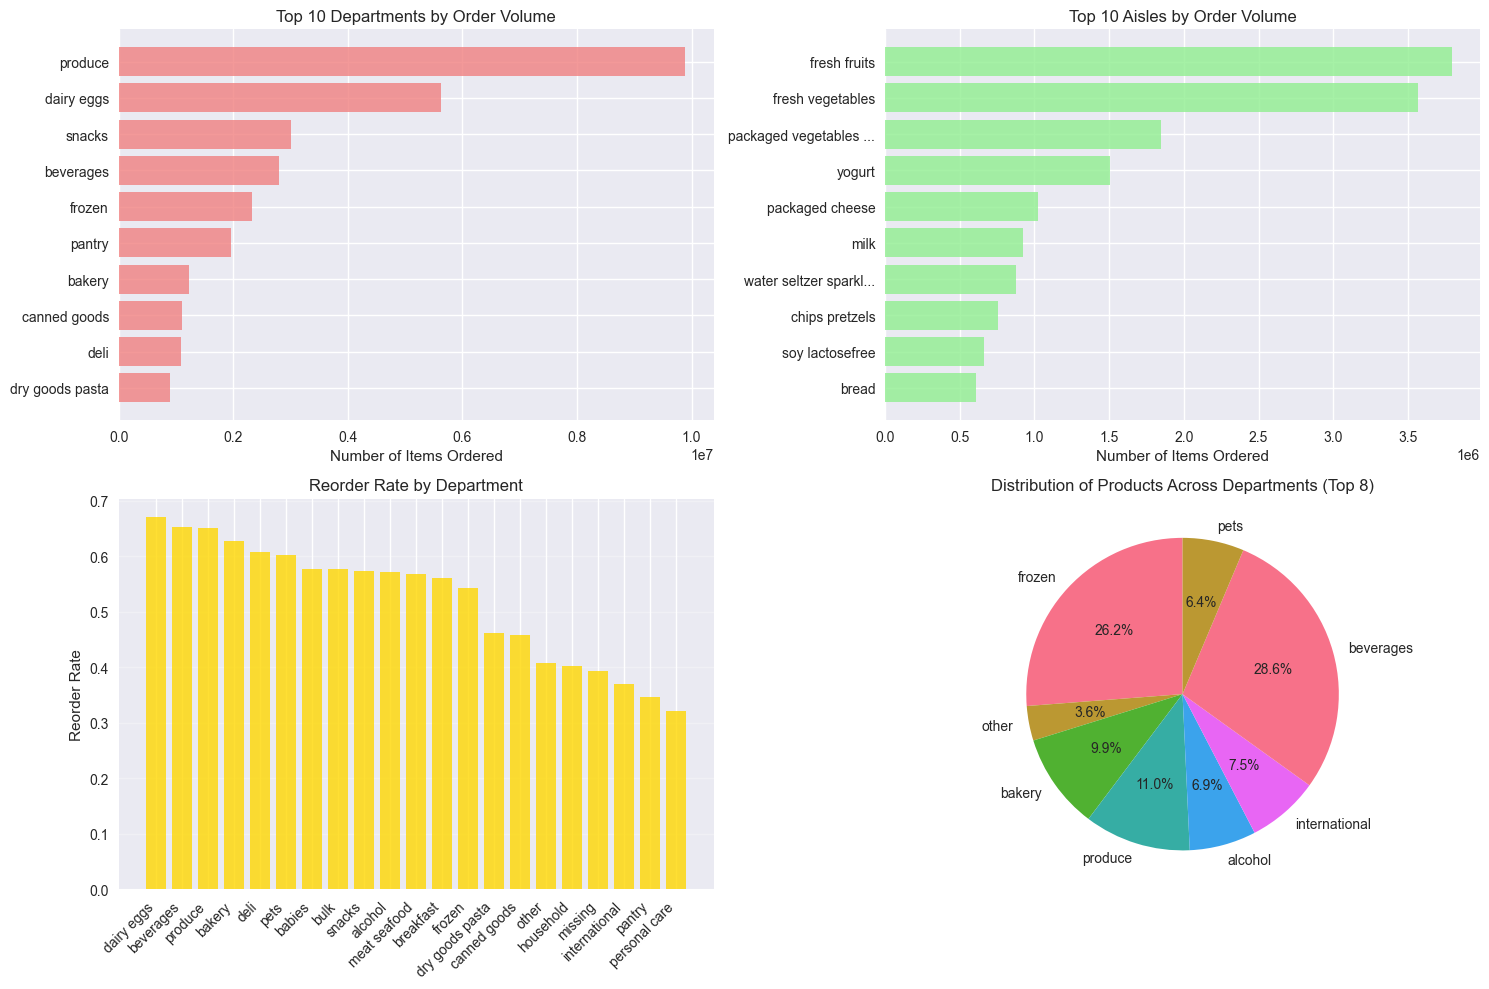


Top department: produce (9888378 items)
Highest reorder rate department: dairy eggs (67.02%)


In [40]:
### 7. Department and Aisle Analysis

print("=== DEPARTMENT AND AISLE ANALYSIS ===")

# 7.1 Orders by Department
dept_orders = items_with_products.groupby('department').size().sort_values(ascending=False)
print("\nTop 10 Departments by Order Volume:")
print(dept_orders.head(10))

plt.figure(figsize=(15, 10))

# Department analysis
plt.subplot(2, 2, 1)
top_depts = dept_orders.head(10)
plt.barh(range(len(top_depts)), top_depts.values, color='lightcoral', alpha=0.8)
plt.yticks(range(len(top_depts)), top_depts.index)
plt.xlabel('Number of Items Ordered')
plt.title('Top 10 Departments by Order Volume')
plt.gca().invert_yaxis()

# Aisle analysis
plt.subplot(2, 2, 2)
aisle_orders = items_with_products.groupby('aisle').size().sort_values(ascending=False)
top_aisles = aisle_orders.head(10)
plt.barh(range(len(top_aisles)), top_aisles.values, color='lightgreen', alpha=0.8)
plt.yticks(
    range(len(top_aisles)), 
    [aisle[:20] + '...' if len(aisle) > 20 else aisle for aisle in top_aisles.index]
)
plt.xlabel('Number of Items Ordered')
plt.title('Top 10 Aisles by Order Volume')
plt.gca().invert_yaxis()

# Reorder rate by department
plt.subplot(2, 2, 3)
dept_reorder = items_with_products.groupby('department')['reordered'].mean().sort_values(ascending=False)
plt.bar(range(len(dept_reorder)), dept_reorder.values, color='gold', alpha=0.8)
plt.xticks(range(len(dept_reorder)), dept_reorder.index, rotation=45, ha='right')
plt.ylabel('Reorder Rate')
plt.title('Reorder Rate by Department')
plt.grid(axis='y', alpha=0.3)

# Products per department (FIXED PART)
plt.subplot(2, 2, 4)
products_per_dept = products.groupby('department_id').size().reset_index(name='count')
dept_products = products_per_dept.merge(departments, on='department_id')

plt.pie(
    dept_products['count'].iloc[:8], 
    labels=dept_products['department'].iloc[:8], 
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Distribution of Products Across Departments (Top 8)')

plt.tight_layout()
plt.show()

print(f"\nTop department: {dept_orders.index[0]} ({dept_orders.iloc[0]} items)")
print(f"Highest reorder rate department: {dept_reorder.index[0]} ({dept_reorder.iloc[0]:.2%})")


In [41]:

### 8. Customer Behavior Analysis

print("=== CUSTOMER BEHAVIOR ANALYSIS ===")

# User ordering patterns
user_stats = order_metadata.groupby('user_id').agg({
    'order_id': 'count',
    'order_number': 'max',
    'days_since_prior_order': 'mean'
}).round(2)
user_stats.columns = ['total_orders', 'max_order_number', 'avg_days_between_orders']

print("\nUser Statistics Summary:")
print(user_stats.describe())

# Customer segments based on ordering frequency
print("\n\nCustomer Segments by Order Frequency:")
frequency_segments = pd.cut(user_stats['total_orders'], 
                          bins=[0, 2, 5, 10, float('inf')],
                          labels=['Low (1-2)', 'Medium (3-5)', 'High (6-10)', 'Very High (>10)'])
print(frequency_segments.value_counts())

# Reorder behavior by user
user_reorder = orders_with_items.groupby('user_id')['reordered'].agg(['mean', 'sum', 'count'])
user_reorder.columns = ['reorder_rate', 'total_reorders', 'total_items']
print("\nUser Reorder Behavior:")
print(user_reorder.describe())


=== CUSTOMER BEHAVIOR ANALYSIS ===

User Statistics Summary:
        total_orders  max_order_number  avg_days_between_orders
count  206209.000000     206209.000000            206209.000000
mean       16.590367         16.590367                15.448673
std        16.654774         16.654774                 6.915575
min         4.000000          4.000000                 0.000000
25%         6.000000          6.000000                 9.810000
50%        10.000000         10.000000                15.000000
75%        20.000000         20.000000                20.620000
max       100.000000        100.000000                30.000000


Customer Segments by Order Frequency:
total_orders
Very High (>10)    101696
High (6-10)         60937
Medium (3-5)        43576
Low (1-2)               0
Name: count, dtype: int64

User Reorder Behavior:
        reorder_rate  total_reorders    total_items
count  206209.000000   206209.000000  206209.000000
mean        0.444332       96.772498     164.004025


In [42]:

### 9. Reorder Patterns Analysis

print("=== REORDER PATTERNS ANALYSIS ===")

# Overall reorder statistics
total_items = len(order_items)
reordered_items = order_items['reordered'].sum()
reorder_rate = reordered_items / total_items

print(f"\nOverall Reorder Statistics:")
print(f"  Total items in dataset: {total_items:,}")
print(f"  Reordered items: {reordered_items:,}")
print(f"  Overall reorder rate: {reorder_rate:.2%}")

# Reorder rate by cart position
print("\nReorder Rate by Cart Position:")
cart_reorder = order_items.groupby('add_to_cart_order')['reordered'].mean()
top_positions = cart_reorder.head(10)
for pos, rate in top_positions.items():
    print(f"  Position {pos:2}: {rate:.2%}")

# Reorder analysis by eval_set
reorder_by_set = orders_with_items.groupby('eval_set')['reordered'].agg(['mean', 'sum', 'count'])
print("\nReorder Statistics by Evaluation Set:")
print(reorder_by_set)


=== REORDER PATTERNS ANALYSIS ===

Overall Reorder Statistics:
  Total items in dataset: 33,819,106
  Reordered items: 19,955,360
  Overall reorder rate: 59.01%

Reorder Rate by Cart Position:
  Position  1: 67.93%
  Position  2: 67.71%
  Position  3: 65.84%
  Position  4: 63.73%
  Position  5: 61.76%
  Position  6: 60.06%
  Position  7: 58.58%
  Position  8: 57.35%
  Position  9: 56.17%
  Position 10: 55.14%

Reorder Statistics by Evaluation Set:
              mean       sum     count
eval_set                              
prior     0.589697  19126536  32434489
train     0.598594    828824   1384617


In [43]:

### 10. Time-based Analysis

print("=== TIME-BASED ANALYSIS ===")

# Order patterns by day and hour combination
print("\nOrder Patterns - Day vs Hour Heatmap Data:")
day_hour_orders = order_metadata.groupby(['order_dow', 'order_hour_of_day']).size().unstack(fill_value=0)

# Days since prior order patterns
print("\nDays Since Prior Order Distribution:")
days_dist = order_metadata['days_since_prior_order'].dropna().value_counts().sort_index().head(15)
for days, count in days_dist.items():
    print(f"  {days:2.0f} days: {count:4} orders ({count/len(order_metadata)*100:.1f}%)")

# Order patterns by order number (customer lifecycle)
print("\nOrder Volume by Customer Order Number:")
order_num_dist = order_metadata['order_number'].value_counts().sort_index().head(10)
for num, count in order_num_dist.items():
    print(f"  Order #{num:2}: {count:4} customers")

# Seasonal patterns (if applicable)
avg_items_by_hour = orders_with_items.groupby('order_hour_of_day').size() / order_metadata.groupby('order_hour_of_day').size()
print(f"\nAverage items per order by hour:")
print(f"  Peak hour for items/order: {avg_items_by_hour.idxmax()}:00 ({avg_items_by_hour.max():.2f} items/order)")
print(f"  Lowest hour for items/order: {avg_items_by_hour.idxmin()}:00 ({avg_items_by_hour.min():.2f} items/order)")


=== TIME-BASED ANALYSIS ===

Order Patterns - Day vs Hour Heatmap Data:

Days Since Prior Order Distribution:
   0 days: 67755 orders (2.0%)
   1 days: 145247 orders (4.2%)
   2 days: 193206 orders (5.6%)
   3 days: 217005 orders (6.3%)
   4 days: 221696 orders (6.5%)
   5 days: 214503 orders (6.3%)
   6 days: 240013 orders (7.0%)
   7 days: 320608 orders (9.4%)
   8 days: 181717 orders (5.3%)
   9 days: 118188 orders (3.5%)
  10 days: 95186 orders (2.8%)
  11 days: 80970 orders (2.4%)
  12 days: 76146 orders (2.2%)
  13 days: 83214 orders (2.4%)
  14 days: 100230 orders (2.9%)

Order Volume by Customer Order Number:
  Order # 1: 206209 customers
  Order # 2: 206209 customers
  Order # 3: 206209 customers
  Order # 4: 206209 customers
  Order # 5: 182223 customers
  Order # 6: 162633 customers
  Order # 7: 146468 customers
  Order # 8: 132618 customers
  Order # 9: 120918 customers
  Order #10: 110728 customers

Average items per order by hour:
  Peak hour for items/order: 22:00 (10.77

In [44]:

### 11. Key Findings and Conclusions

print("=== KEY FINDINGS AND CONCLUSIONS ===")
print("\n" + "="*60)
print("QUICKBASKET GROCERY DATA - EXPLORATORY ANALYSIS SUMMARY")
print("="*60)

print("\n1. 📊 DATASET OVERVIEW:")
print(f"   • Analyzed {len(order_metadata):,} orders from {order_metadata['user_id'].nunique():,} unique customers")
print(f"   • Dataset contains {len(order_items):,} individual order items")
print(f"   • Product catalog includes {len(products):,} products across {len(departments):,} departments and {len(aisles):,} aisles")

print("\n2. 🕒 TEMPORAL PATTERNS:")
dow_counts = order_metadata['order_dow'].value_counts().sort_index()
hour_counts = order_metadata['order_hour_of_day'].value_counts().sort_index()
days = ['Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday']
print(f"   • Peak ordering day: {days[dow_counts.idxmax()]} ({dow_counts.max():,} orders)")
print(f"   • Peak ordering hour: {hour_counts.idxmax()}:00 ({hour_counts.max():,} orders)")
print(f"   • Average days between orders: {order_metadata['days_since_prior_order'].mean():.1f} days")

print("\n3. 🛒 SHOPPING BEHAVIOR:")
order_sizes = order_items.groupby('order_id').size()
reorder_rate = order_items['reordered'].mean()
print(f"   • Average items per order: {order_sizes.mean():.1f}")
print(f"   • Overall reorder rate: {reorder_rate:.1%}")
print(f"   • Largest single order: {order_sizes.max()} items")

print("\n4. 🏪 PRODUCT INSIGHTS:")
items_with_products = order_items.merge(products, on='product_id')
items_with_products = items_with_products.merge(departments, on='department_id')
top_dept = items_with_products.groupby('department').size().sort_values(ascending=False)
print(f"   • Most popular department: {top_dept.index[0]} ({top_dept.iloc[0]:,} items)")
dept_reorder = items_with_products.groupby('department')['reordered'].mean().sort_values(ascending=False)
print(f"   • Highest reorder rate department: {dept_reorder.index[0]} ({dept_reorder.iloc[0]:.1%})")

print("\n5. 👥 CUSTOMER SEGMENTS:")
user_stats = order_metadata.groupby('user_id')['order_id'].count()
print(f"   • Average orders per customer: {user_stats.mean():.1f}")
print(f"   • Most loyal customer: {user_stats.max()} orders")

print("\n6. 🎯 BUSINESS RECOMMENDATIONS:")
print("   • Focus marketing efforts on weekend shopping (especially Sunday)")
print("   • Optimize delivery capacity for 10-16 hour window (peak ordering)")
print("   • Leverage high reorder rates for subscription/auto-delivery services")
print(f"   • Develop targeted campaigns for {top_dept.index[0]} department products")
print("   • Implement personalized recommendations based on reorder patterns")

print("\n7. 📈 AREAS FOR FURTHER ANALYSIS:")
print("   • Customer lifetime value analysis")
print("   • Market basket analysis for product associations")
print("   • Seasonal demand forecasting")
print("   • Price sensitivity analysis")
print("   • Customer churn prediction modeling")

print("\n" + "="*60)
print("Analysis completed successfully! 🎉")
print("="*60)


=== KEY FINDINGS AND CONCLUSIONS ===

QUICKBASKET GROCERY DATA - EXPLORATORY ANALYSIS SUMMARY

1. 📊 DATASET OVERVIEW:
   • Analyzed 3,421,083 orders from 206,209 unique customers
   • Dataset contains 33,819,106 individual order items
   • Product catalog includes 49,688 products across 21 departments and 134 aisles

2. 🕒 TEMPORAL PATTERNS:
   • Peak ordering day: Sunday (600,905 orders)
   • Peak ordering hour: 10:00 (288,418 orders)
   • Average days between orders: 11.1 days

3. 🛒 SHOPPING BEHAVIOR:
   • Average items per order: 10.1
   • Overall reorder rate: 59.0%
   • Largest single order: 145 items

4. 🏪 PRODUCT INSIGHTS:
   • Most popular department: produce (9,888,378 items)
   • Highest reorder rate department: dairy eggs (67.0%)

5. 👥 CUSTOMER SEGMENTS:
   • Average orders per customer: 16.6
   • Most loyal customer: 100 orders

6. 🎯 BUSINESS RECOMMENDATIONS:
   • Focus marketing efforts on weekend shopping (especially Sunday)
   • Optimize delivery capacity for 10-16 hour w

1. Total number of orders and unique customers
Total Orders: 3421083
Unique Customers: 206209
2. Unique products, aisles, departments
Unique Products: 49688
Unique Aisles: 134
Unique Departments: 21
3. Top 20 most frequently ordered products

Top 20 Products:
 product_name
Banana                      491291
Bag of Organic Bananas      394930
Organic Strawberries        275577
Organic Baby Spinach        251705
Organic Hass Avocado        220877
Organic Avocado             184224
Large Lemon                 160792
Strawberries                149445
Limes                       146660
Organic Whole Milk          142813
Organic Raspberries         142603
Organic Yellow Onion        117716
Organic Garlic              113936
Organic Zucchini            109412
Organic Blueberries         105026
Cucumber Kirby               99728
Organic Fuji Apple           92889
Organic Lemon                91251
Organic Grape Tomatoes       88078
Apple Honeycrisp Organic     87272
Name: count, dtype: int64


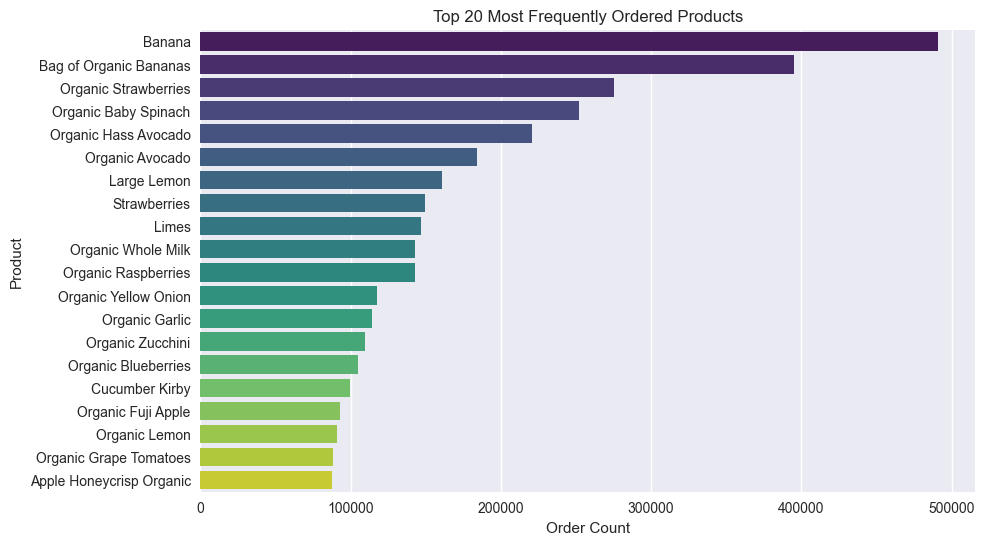

4. Top departments and aisles by order volume


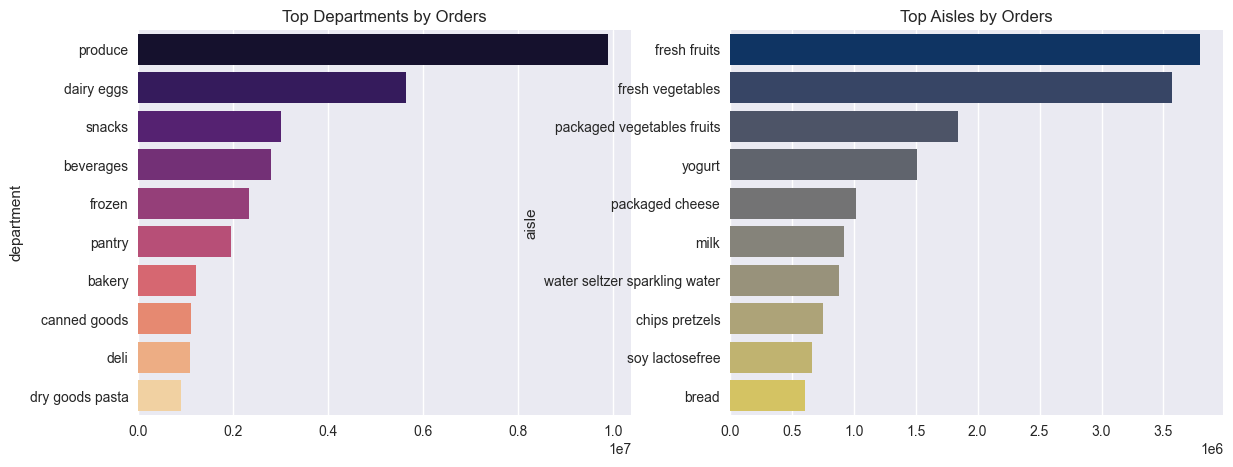

5. Most reordered products

Most Reordered Products:
 product_name
Raw Veggie Wrappers                         0.942029
Serenity Ultimate Extrema Overnight Pads    0.933333
Orange Energy Shots                         0.923077
Chocolate Love Bar                          0.921569
Soy Powder Infant Formula                   0.914286
Simply Sleep Nighttime Sleep Aid            0.911111
Energy Shot, Grape Flavor                   0.909091
Russian River Valley Reserve Pinot Noir     0.900000
Bars Peanut Butter                          0.898551
Soy Crisps Lightly Salted                   0.895522
High Gravity Lager                          0.894737
Maca Buttercups                             0.894231
Almond Orgeat Syrup                         0.892857
Benchbreak Chardonnay                       0.891892
Organic Blueberry B Mega                    0.888889
Sparking Water                              0.887097
Very Rare Blended  Scotch Whisky            0.880952
Amazake Almond Shake            

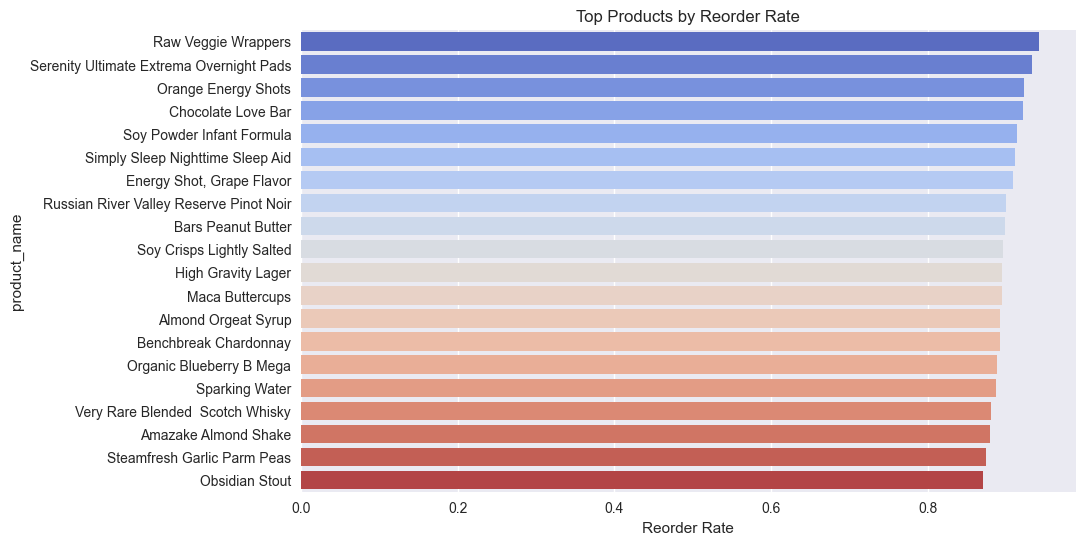

6. Average basket size

Average Basket Size: 10.11 items/order
7. Order trends (hour of day, day of week, days since prior order)


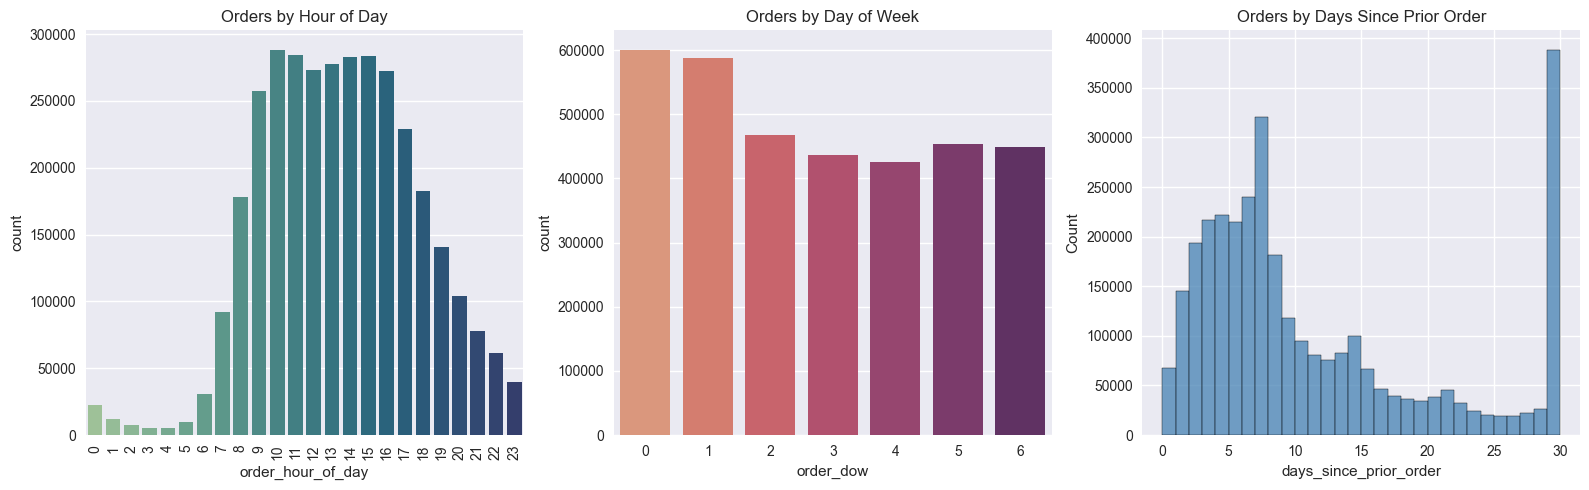

In [48]:
# -------------------------------
# Task 1: Exploratory Data Analysis (QuickBasket)
# -------------------------------

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Merge product, aisle, and department info into order_items
items_with_products = (
    order_items
    .merge(products, on="product_id", how="left")
    .merge(aisles, on="aisle_id", how="left")
    .merge(departments, on="department_id", how="left")
)

print("1. Total number of orders and unique customers")
total_orders = order_metadata["order_id"].nunique()
unique_customers = order_metadata["user_id"].nunique()
print(f"Total Orders: {total_orders}")
print(f"Unique Customers: {unique_customers}")

print("2. Unique products, aisles, departments")
print(f"Unique Products: {products['product_id'].nunique()}")
print(f"Unique Aisles: {aisles['aisle_id'].nunique()}")
print(f"Unique Departments: {departments['department_id'].nunique()}")

print("3. Top 20 most frequently ordered products")
top_products = items_with_products["product_name"].value_counts().head(20)
print("\nTop 20 Products:\n", top_products)
plt.figure(figsize=(10,6))
sns.barplot(y=top_products.index, x=top_products.values, palette="viridis")
plt.title("Top 20 Most Frequently Ordered Products")
plt.xlabel("Order Count")
plt.ylabel("Product")
plt.show()

print("4. Top departments and aisles by order volume")
dept_orders = items_with_products["department"].value_counts().head(10)
aisle_orders = items_with_products["aisle"].value_counts().head(10)

plt.figure(figsize=(14,5))
plt.subplot(1,2,1)
sns.barplot(y=dept_orders.index, x=dept_orders.values, palette="magma")
plt.title("Top Departments by Orders")

plt.subplot(1,2,2)
sns.barplot(y=aisle_orders.index, x=aisle_orders.values, palette="cividis")
plt.title("Top Aisles by Orders")
plt.show()

print("5. Most reordered products")
reorder_rate = (
    items_with_products
    .groupby("product_name")["reordered"]
    .mean()
    .sort_values(ascending=False)
    .head(20)
)
print("\nMost Reordered Products:\n", reorder_rate)
plt.figure(figsize=(10,6))
sns.barplot(y=reorder_rate.index, x=reorder_rate.values, palette="coolwarm")
plt.title("Top Products by Reorder Rate")
plt.xlabel("Reorder Rate")
plt.show()

print("6. Average basket size")
basket_size = order_items.groupby("order_id").size().mean()
print(f"\nAverage Basket Size: {basket_size:.2f} items/order")

print("7. Order trends (hour of day, day of week, days since prior order)")
plt.figure(figsize=(16,5))

plt.subplot(1,3,1)
sns.countplot(x="order_hour_of_day", data=order_metadata, palette="crest")
plt.title("Orders by Hour of Day")
plt.xticks(rotation=90)

plt.subplot(1,3,2)
sns.countplot(x="order_dow", data=order_metadata, palette="flare")
plt.title("Orders by Day of Week")

plt.subplot(1,3,3)
sns.histplot(order_metadata["days_since_prior_order"].dropna(), bins=30, kde=False, color="steelblue")
plt.title("Orders by Days Since Prior Order")

plt.tight_layout()
plt.show()
